In [1]:
!pip install pandas openpyxl
import pandas as pd
import numpy as np
# Load Excel file
data= pd.read_excel("C:/Users/HP/Downloads/Malaria_Data.xlsx")
print(data)

Defaulting to user installation because normal site-packages is not writeable
         Continent    Country  Year  Malaria cases  Malaria deaths  \
0    South America  Argentina  2000            440               0   
1    South America  Argentina  2001            215               0   
2    South America  Argentina  2002            125               0   
3    South America  Argentina  2003            124               1   
4    South America  Argentina  2004            116               0   
..             ...        ...   ...            ...             ...   
248  South America  Venezuela  2018         474766             373   
249  South America  Venezuela  2019         466830             350   
250  South America  Venezuela  2020         223067             196   
251  South America  Venezuela  2021         204424             155   
252  South America  Venezuela  2022         154089             125   

     Malaria incidence  Malaria mortality  Indigenous cases  P. falciparum  \
0  

In [14]:

import pandas as pd

# 1. Read Excel file
data = pd.read_excel("C:/Users/HP/Downloads/Malaria_Data.xlsx", sheet_name="data")
var = pd.read_excel("C:/Users/HP/Downloads/Malaria_Data.xlsx", sheet_name="variable", header=2)

rows = []

def add(category, item, information):
    rows.append([category, item, information])

# 2. Dataset Information
add("Dataset Information", "Study Area", "South America")
add("Dataset Information", "Total Countries", data["Country"].nunique())
add("Dataset Information", "Countries",
    ", ".join(sorted(data["Country"].unique())))
add("Dataset Information", "Study Period",
    f'{data["Year"].min()}-{data["Year"].max()}')
add("Dataset Information", "Total Years", data["Year"].nunique())
add("Dataset Information", "Total Observations", len(data))
add("Dataset Information", "Total Variables", len(data.columns))

# 3. Data Quality
add("Data Quality", "Missing Values", int(data.isnull().sum().sum()))
add("Data Quality", "Duplicate Observations",
    int(data.duplicated(["Country", "Year"]).sum()))

# 4. Descriptive Statistics
y = data["Malaria cases"]

add("Descriptive Statistics", "Total Malaria Cases", int(y.sum()))
add("Descriptive Statistics", "Mean", round(y.mean(), 2))
add("Descriptive Statistics", "Median", round(y.median(), 2))
add("Descriptive Statistics", "Standard Deviation", round(y.std(), 2))
add("Descriptive Statistics", "Minimum", int(y.min()))
add("Descriptive Statistics", "Maximum", int(y.max()))
add("Descriptive Statistics", "Zero Observations", int((y == 0).sum()))

# 5. Training and Testing Information
train = data[data["Year"].between(2000, 2017)]
test = data[data["Year"].between(2018, 2022)]

add("Data Division", "Training Period", "2000-2017")
add("Data Division", "Training Observations", len(train))
add("Data Division", "Testing Period", "2018-2022")
add("Data Division", "Testing Observations", len(test))

# 6. Country-wise Malaria Cases (All Countries)
country_total = (
    data.groupby("Country")["Malaria cases"]
    .sum()
    .sort_values(ascending=False)
)

for country, total in country_total.items():
    add("Country-wise Malaria Cases", country, int(total))

# 7. Variable Information (All Variables)
for _, r in var.iterrows():
    code = str(r["Code"]).strip()
    description = str(r["Variables"]).strip()
    category = str(r["Category"]).strip()

    if code in data.columns:
        add("Variable Information", code, description)

# 8. Create ONE Combined Table
table = pd.DataFrame(
    rows,
    columns=["Category", "Item", "Information"]
)

# Display complete table
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

print("COMPLETE MALARIA DATASET INFORMATION")
display(table)

# 9. Save as Excel
table.to_excel("Complete_Malaria_Dataset_Information.xlsx",
               index=False)

print("\nTotal countries:", len(country_total))
print("Total variables described:",
      sum(1 for r in rows if r[0] == "Variable Information"))
print("Total information rows:", len(table))
print("Excel file saved successfully!")


COMPLETE MALARIA DATASET INFORMATION


,Category,Item,Information
0,Dataset Information,Study Area,South America
1,Dataset Information,Total Countries,11
2,Dataset Information,Countries,"Argentina, Bolivia, Brazil, Colombia, Ecuador, French Guiana, Guyana, Paraguay, Peru, Suriname, Venezuela"
3,Dataset Information,Study Period,2000-2022
4,Dataset Information,Total Years,23
5,Dataset Information,Total Observations,253
6,Dataset Information,Total Variables,32
7,Data Quality,Missing Values,0
8,Data Quality,Duplicate Observations,0
9,Descriptive Statistics,Total Malaria Cases,17545726



Total countries: 11
Total variables described: 29
Total information rows: 60
Excel file saved successfully!


In [8]:
#EDA test
# Select numerical variables
numeric_df = data.select_dtypes(include=np.number)

# Descriptive statistics
desc = numeric_df.describe().T

# Add additional statistics
desc["Variance"] = numeric_df.var()
desc["Skewness"] = numeric_df.skew()
desc["Kurtosis"] = numeric_df.kurtosis()
desc["Zero_Count"] = (numeric_df == 0).sum()
desc["Missing"] = numeric_df.isnull().sum()

# Display table
print(desc.round(3))

                   count          mean           std       min         25%  \
Year               253.0  2.011000e+03  6.646000e+00    2000.0    2005.000   
Malaria cases      253.0  6.935070e+04  1.236817e+05       0.0     692.000   
Malaria deaths     253.0  3.436000e+01  5.782700e+01       0.0       0.000   
Malaria incidence  253.0  1.439700e+01  2.692300e+01       0.0       1.480   
Malaria mortality  253.0  1.361000e+00  3.897000e+00       0.0       0.000   
Indigenous cases   253.0  7.488728e+04  2.606356e+05       0.0       0.000   
P. falciparum      253.0  3.705362e+04  1.795937e+05       0.0       0.000   
 P. vivax          253.0  2.042638e+04  5.485450e+04       0.0       0.000   
y1                 253.0  7.293000e+00  1.223200e+01       0.0       0.000   
y2                 253.0  1.415000e+00  1.250000e+00       0.0       0.000   
y3                 253.0  1.282500e+01  1.169800e+01       0.0       3.064   
y4                 253.0  1.282500e+01  1.169800e+01       0.0  

In [9]:
#Country wise describetive

country_stats = data.groupby("Country").describe()
print(country_stats)

#Year wise describtive 
year_stats = data.groupby("Year").mean(numeric_only=True)
print(year_stats)

               Year                                                           \
              count    mean      std     min     25%     50%     75%     max   
Country                                                                        
Argentina      23.0  2011.0  6.78233  2000.0  2005.5  2011.0  2016.5  2022.0   
Bolivia        23.0  2011.0  6.78233  2000.0  2005.5  2011.0  2016.5  2022.0   
Brazil         23.0  2011.0  6.78233  2000.0  2005.5  2011.0  2016.5  2022.0   
Colombia       23.0  2011.0  6.78233  2000.0  2005.5  2011.0  2016.5  2022.0   
Ecuador        23.0  2011.0  6.78233  2000.0  2005.5  2011.0  2016.5  2022.0   
French Guiana  23.0  2011.0  6.78233  2000.0  2005.5  2011.0  2016.5  2022.0   
Guyana         23.0  2011.0  6.78233  2000.0  2005.5  2011.0  2016.5  2022.0   
Paraguay       23.0  2011.0  6.78233  2000.0  2005.5  2011.0  2016.5  2022.0   
Peru           23.0  2011.0  6.78233  2000.0  2005.5  2011.0  2016.5  2022.0   
Suriname       23.0  2011.0  6.78233  20

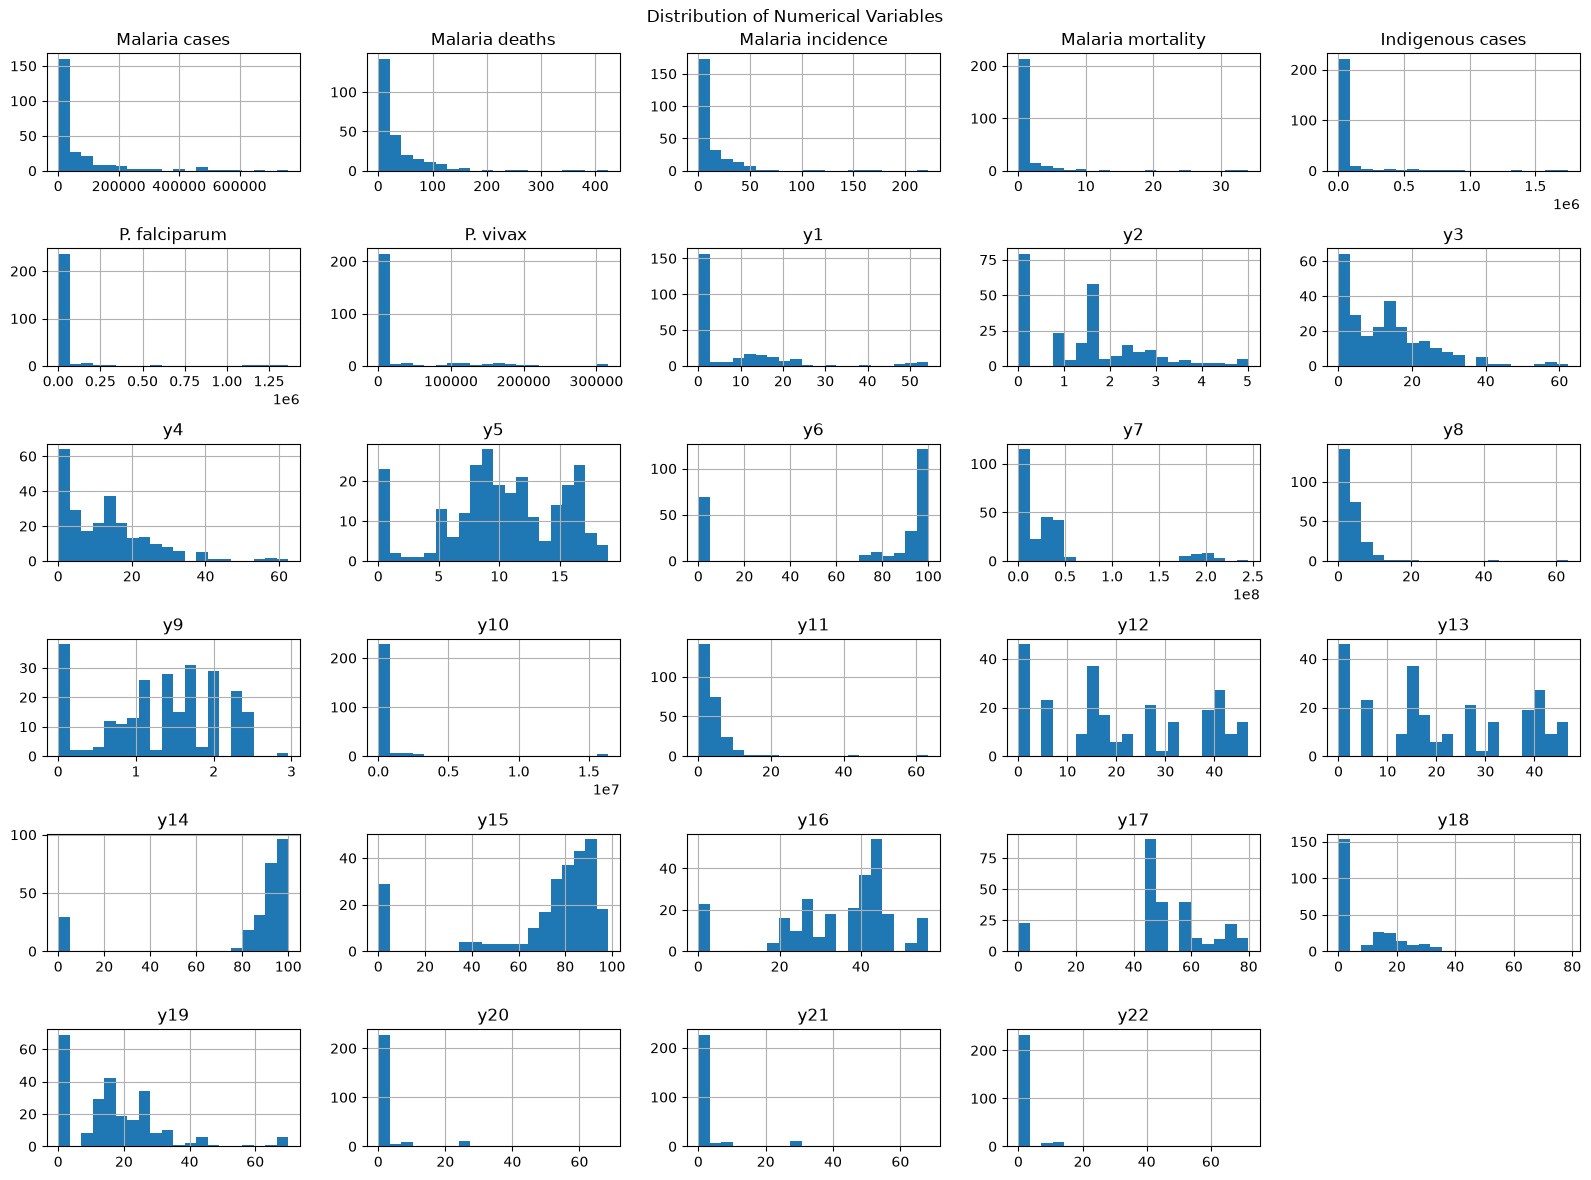

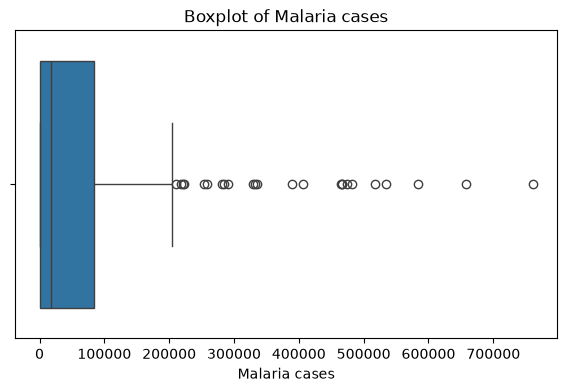

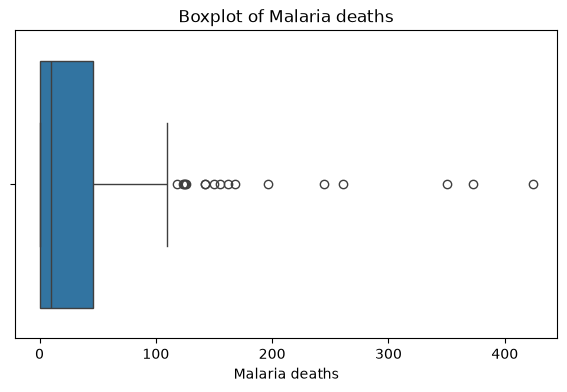

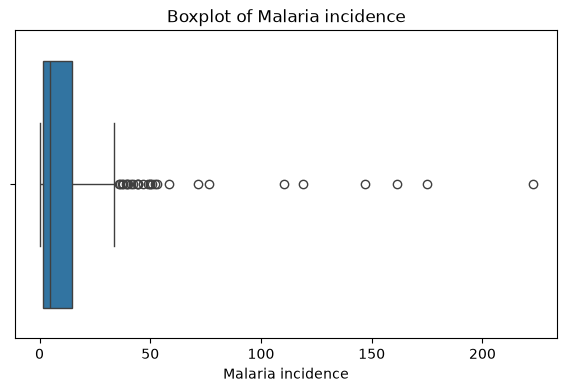

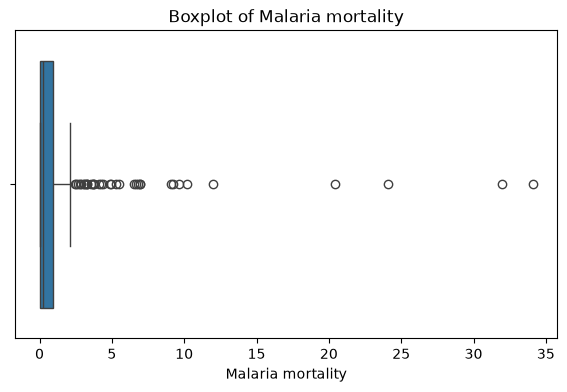

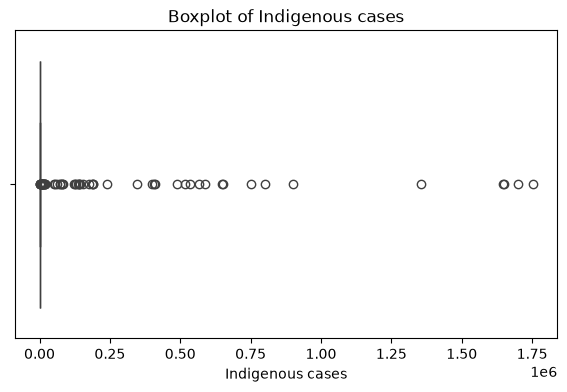

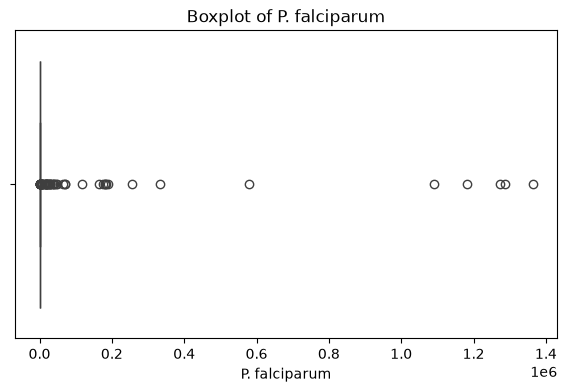

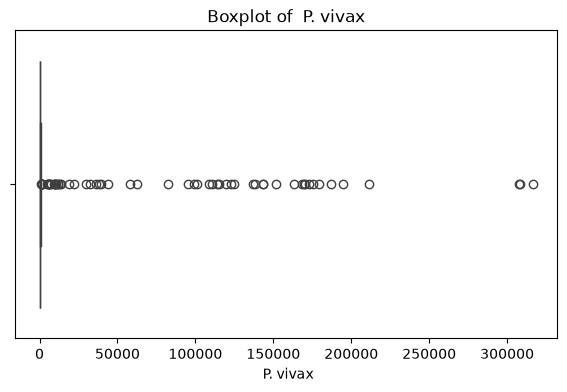

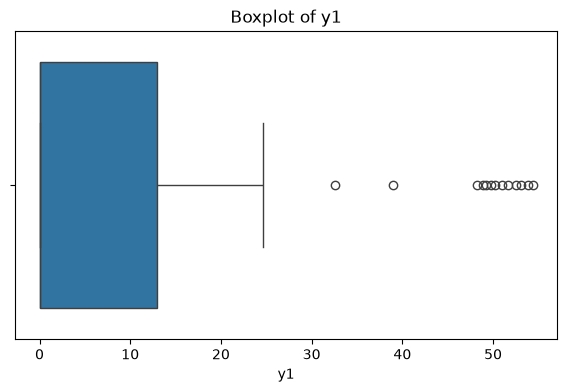

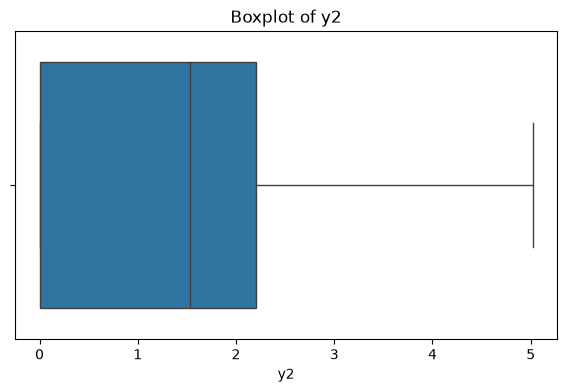

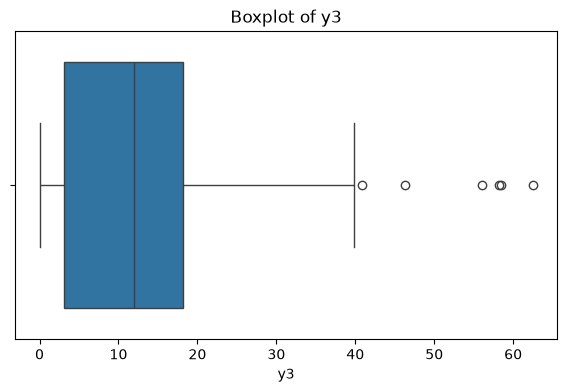

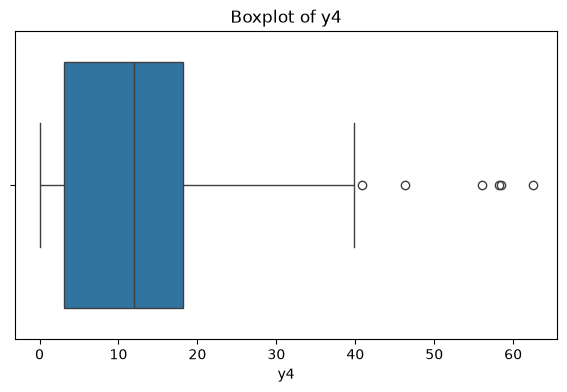

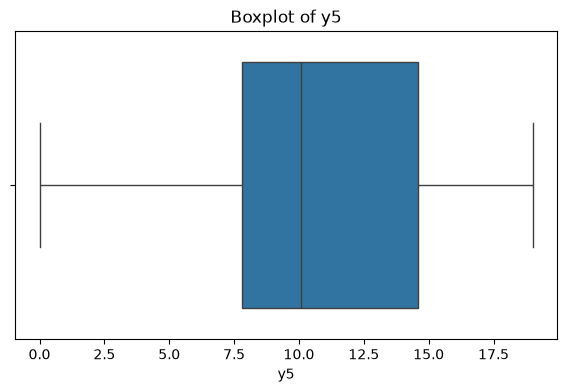

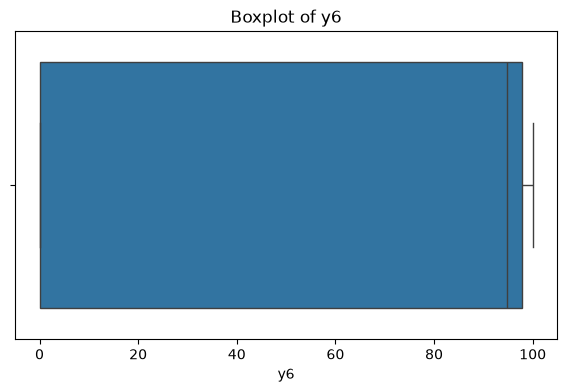

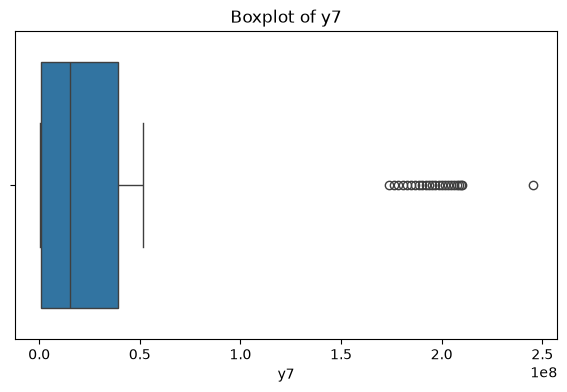

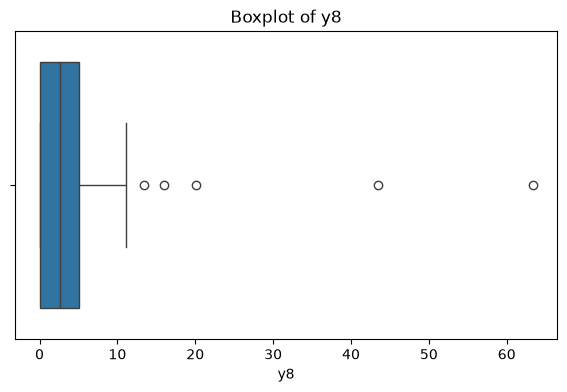

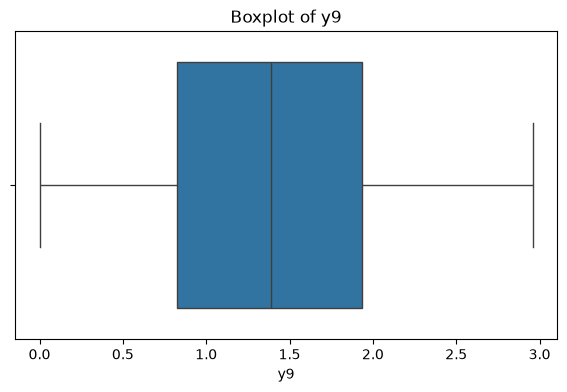

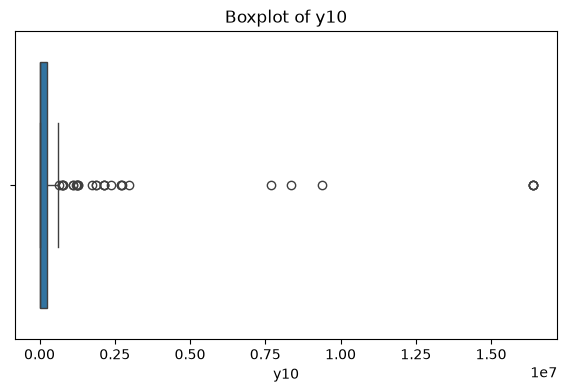

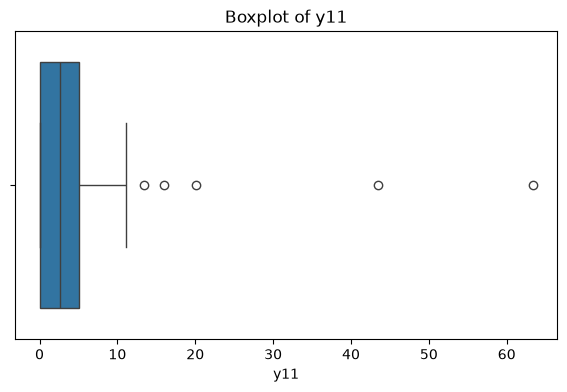

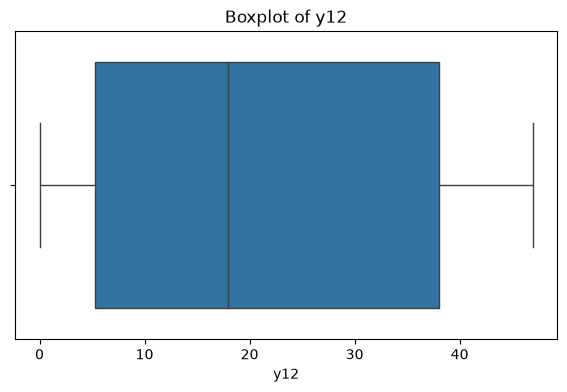

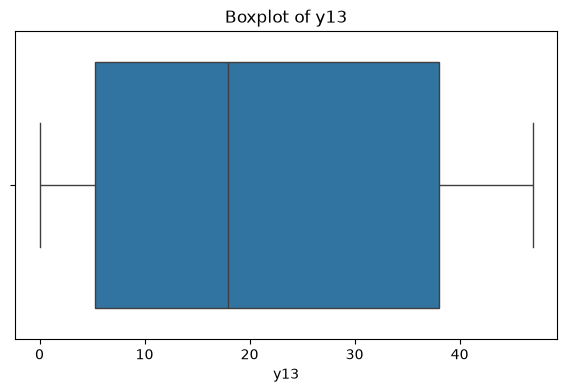

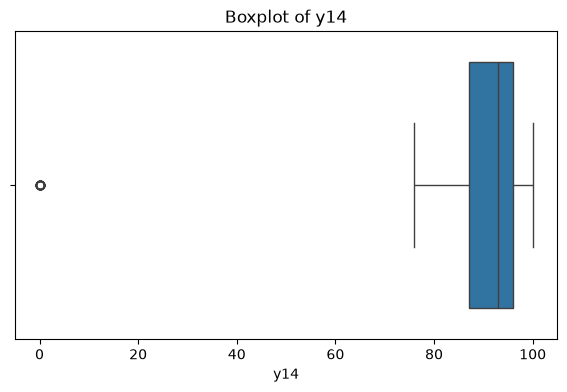

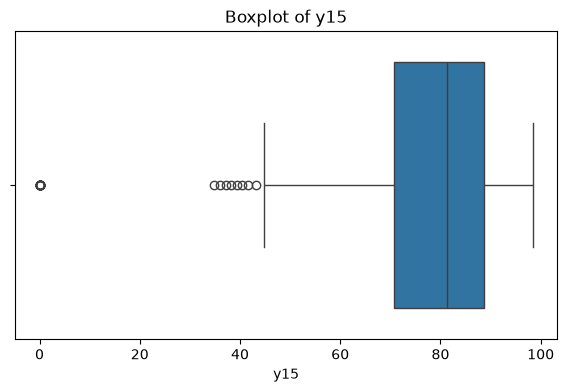

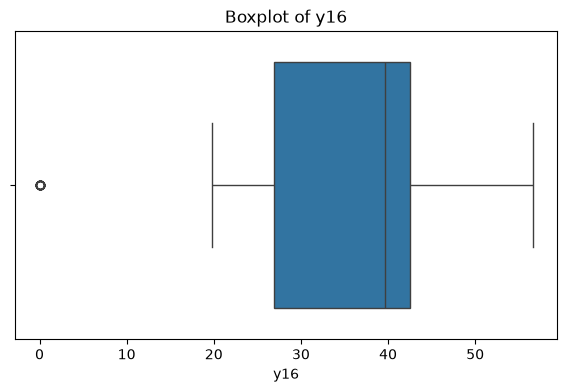

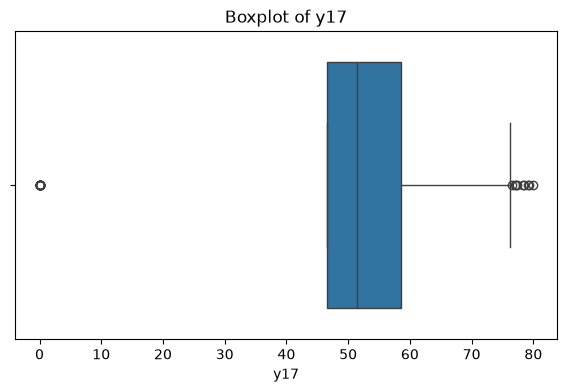

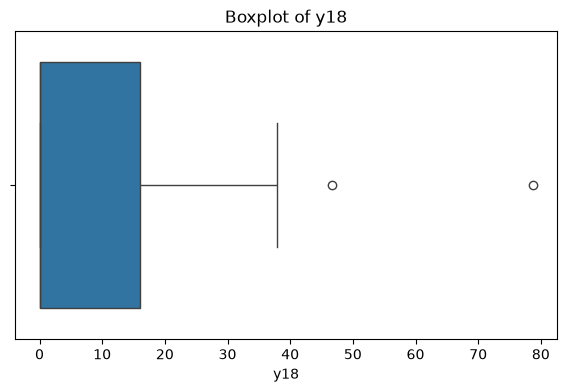

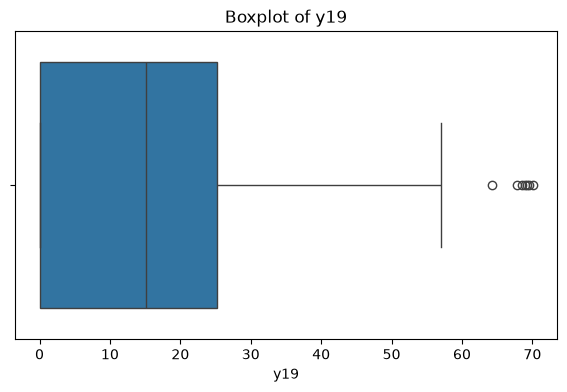

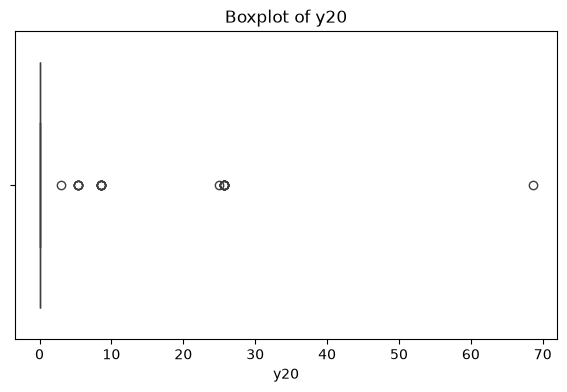

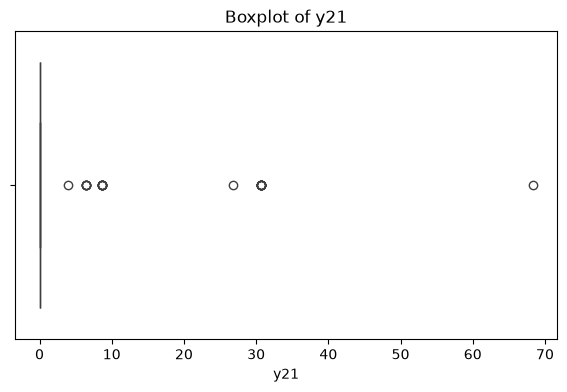

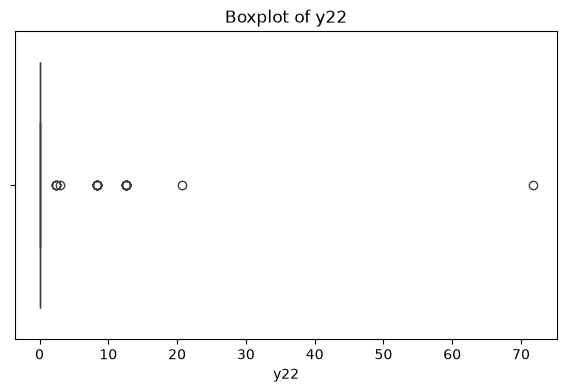

In [11]:
##distribution analysis

import matplotlib.pyplot as plt
import seaborn as sns


# Select numerical variables
numeric_df = data.select_dtypes(include="number")

# Remove Year column if present
num_vars = [col for col in numeric_df.columns
            if col.lower() != "year"]

# Histogram
numeric_df[num_vars].hist(figsize=(16, 12), bins=20)
plt.suptitle("Distribution of Numerical Variables")
plt.tight_layout()
plt.show()

# Boxplot
for col in num_vars:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x=data[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [12]:
##out lier detection

outlier_result = []

for col in num_vars:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((data[col] < lower) | (data[col] > upper)).sum()

    outlier_result.append({
        "Variable": col,
        "Lower Limit": lower,
        "Upper Limit": upper,
        "Outlier Count": outliers
    })

outlier_table = pd.DataFrame(outlier_result)
print(outlier_table.round(3))

             Variable   Lower Limit   Upper Limit  Outlier Count
0       Malaria cases -1.241740e+05  2.088020e+05             24
1      Malaria deaths -6.900000e+01  1.150000e+02             17
2   Malaria incidence -1.827500e+01  3.440500e+01             28
3   Malaria mortality -1.380000e+00  2.300000e+00             35
4    Indigenous cases -9.405000e+02  1.567500e+03             60
5       P. falciparum -4.650000e+01  7.750000e+01             57
6            P. vivax -6.270000e+02  1.045000e+03             60
7                  y1 -1.944000e+01  3.240000e+01             13
8                  y2 -3.300000e+00  5.500000e+00              0
9                  y3 -1.954600e+01  4.074600e+01              6
10                 y4 -1.954600e+01  4.074600e+01              6
11                 y5 -2.350000e+00  2.477000e+01              0
12                 y6 -1.467000e+02  2.445000e+02              0
13                 y7 -5.690399e+07  9.688925e+07             24
14                 y8 -7.

               Malaria cases  Malaria deaths  Malaria incidence  \
Country                                                           
Argentina             87.043           0.043              0.449   
Bolivia            16612.130           7.304              3.726   
Brazil            334889.826          78.478              8.749   
Colombia          143416.304          54.130             14.858   
Ecuador            19190.174          15.261              2.560   
French Guiana       2283.913           1.478             20.413   
Guyana             30389.478          42.522             39.655   
Paraguay             755.478           0.000              4.005   
Peru               71203.957          56.217              6.270   
Suriname            3579.522           4.130             48.056   
Venezuela         140449.826         118.391              9.632   

               Malaria mortality  Indigenous cases  P. falciparum   P. vivax  \
Country                                         

C:\Users\HP\AppData\Local\Temp\ipykernel_20176\2723093316.py:19: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()


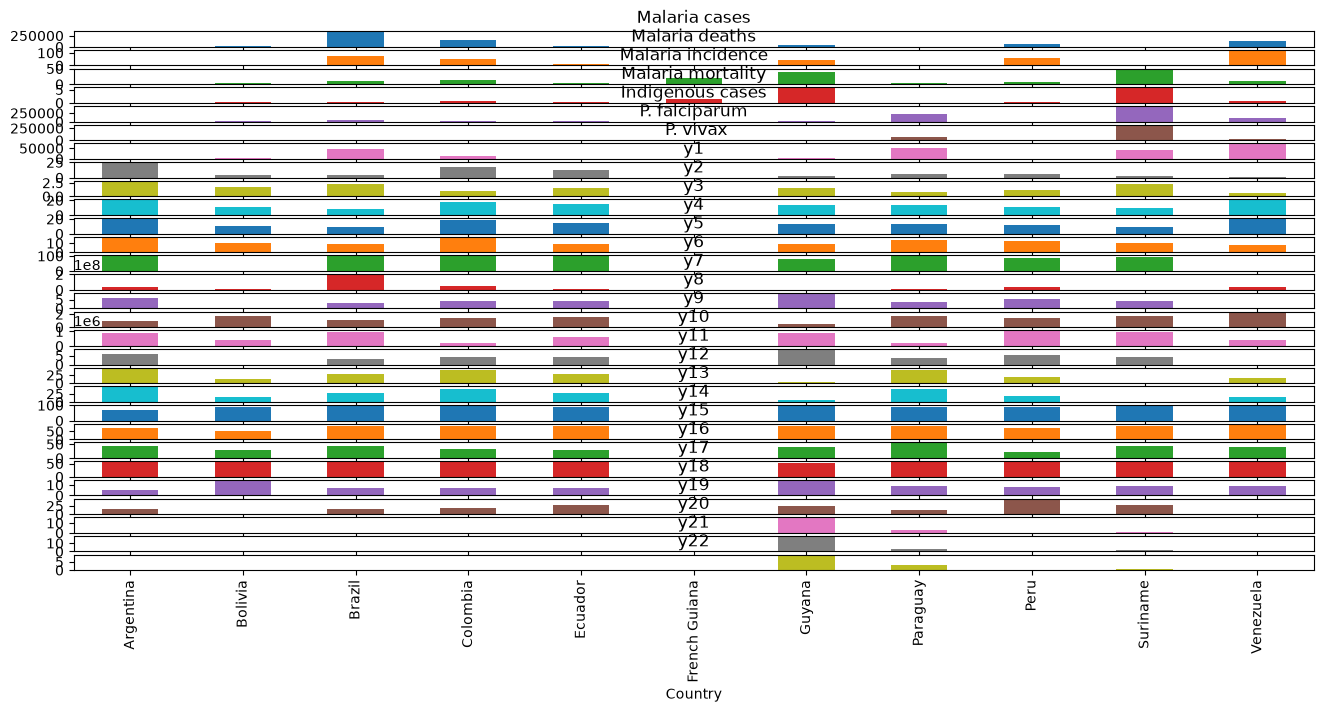

In [15]:
###country wise analysis
# Find country column automatically
country_col = next(
    (c for c in data.columns if c.lower() in
     ["country", "countries", "entity"]),
    None
)

if country_col:
    country_mean = data.groupby(country_col)[num_vars].mean()

    print(country_mean.round(3))

    country_mean.plot(
        kind="bar", figsize=(16, 7), subplots=True,
        layout=(len(num_vars), 1), legend=False
    )

    plt.tight_layout()
    plt.show()
else:
    print("Country column not found. Check data.columns.")

Available columns: ['Continent', 'Country', 'Year', 'Malaria cases', 'Malaria deaths', 'Malaria incidence', 'Malaria mortality', 'Indigenous cases', 'P. falciparum', 'P. vivax', 'y1', 'y2', 'y3', 'y4', 'y5', 'y6', 'y7', 'y8', 'y9', 'y10', 'y11', 'y12', 'y13', 'y14', 'y15', 'y16', 'y17', 'y18', 'y19', 'y20', 'y21', 'y22']


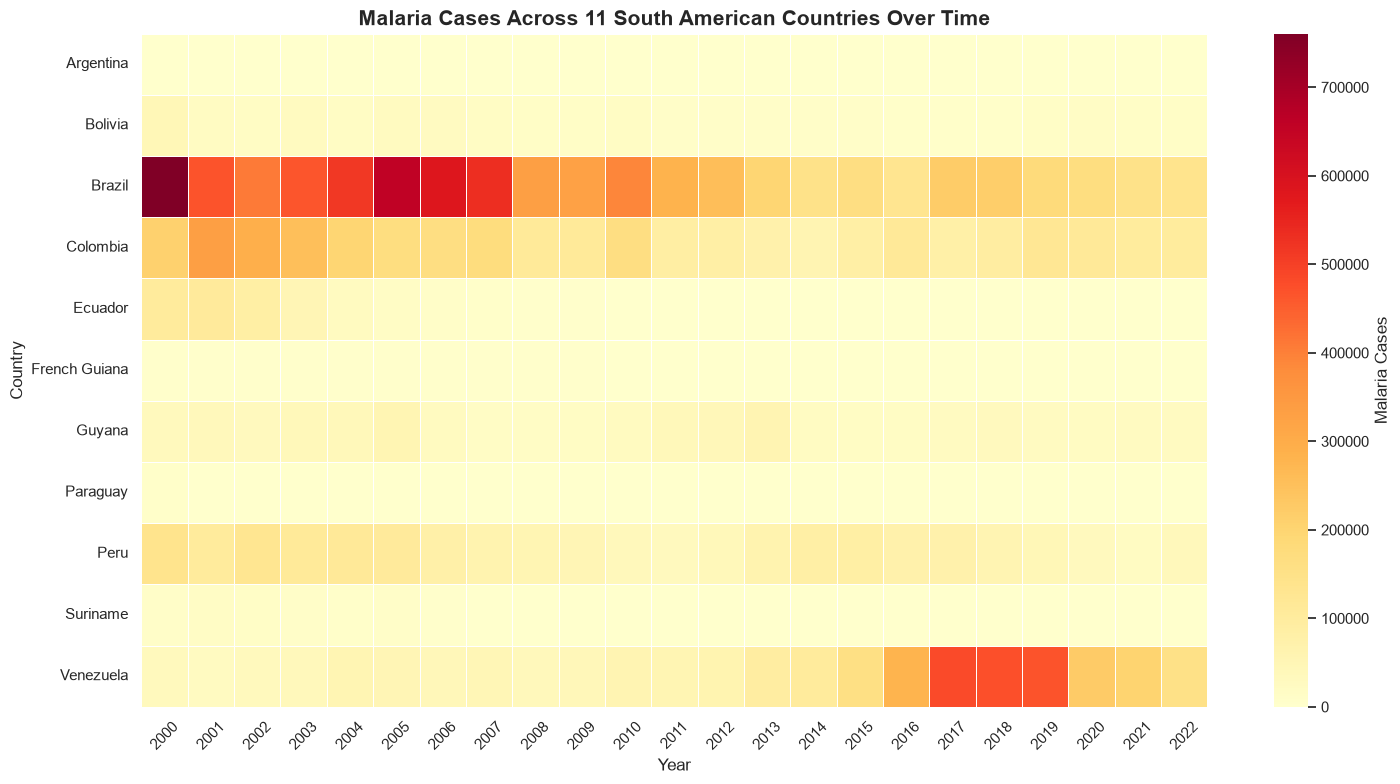

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Excel file
df = pd.read_excel("C:/Users/HP/Downloads/Malaria_Data.xlsx")

# 2. Clean column names
df.columns = df.columns.str.strip()

print("Available columns:", df.columns.tolist())

# 3. Select required columns
country_col = "Country"
year_col = "Year"
cases_col = "Malaria cases"

# 4. Convert data into numeric format
df[year_col] = pd.to_numeric(df[year_col], errors="coerce")
df[cases_col] = pd.to_numeric(df[cases_col], errors="coerce")

# 5. Remove missing observations
df = df.dropna(subset=[country_col, year_col, cases_col])

# 6. Create pivot table
pivot = df.pivot_table(
    index=country_col,
    columns=year_col,
    values=cases_col,
    aggfunc="sum"
)

# 7. Create heatmap
plt.figure(figsize=(15, 8))

sns.heatmap(
    pivot,
    cmap="YlOrRd",
    annot=False,
    linewidths=0.5,
    cbar_kws={"label": "Malaria Cases"}
)

# 8. Add title and labels
plt.title(
    "Malaria Cases Across 11 South American Countries Over Time",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Year", fontsize=12)
plt.ylabel("Country", fontsize=12)

plt.xticks(rotation=45)
plt.yticks(rotation=0)

# 9. Save and display
plt.tight_layout()
plt.savefig("Malaria_Heatmap.png", dpi=300)
plt.show()

In [18]:
!pip install geopandas pandas

Defaulting to user installation because normal site-packages is not writeable


      Malaria cases  Malaria deaths  Malaria incidence  Malaria mortality  \
Year                                                                        
2000     122878.455          63.727             34.826              4.168   
2001     101974.909          54.364             38.191              4.252   
2002      92717.000          47.273             31.830              2.940   
2003      91322.636          44.727             28.842              3.645   
2004      89699.273          42.364             23.607              1.851   
2005      99906.091          39.091             26.134              1.359   
2006      85964.000          31.000             15.950              1.189   
2007      79207.273          26.000             12.401              0.908   
2008      52602.000          19.818             10.208              0.552   
2009      52313.091          20.091             10.741              0.521   
2010      64041.364          23.182             10.540              0.938   

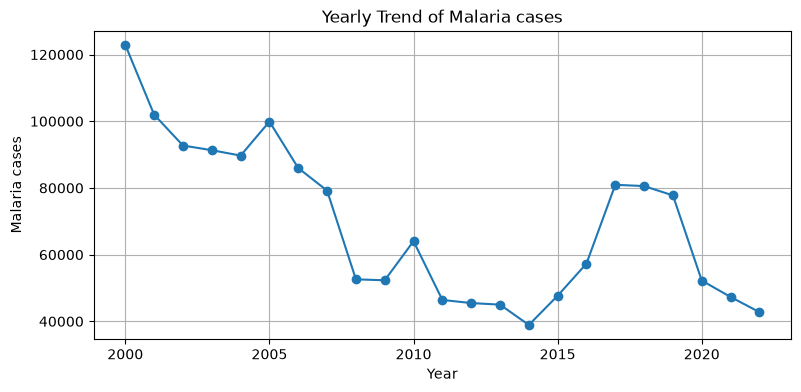

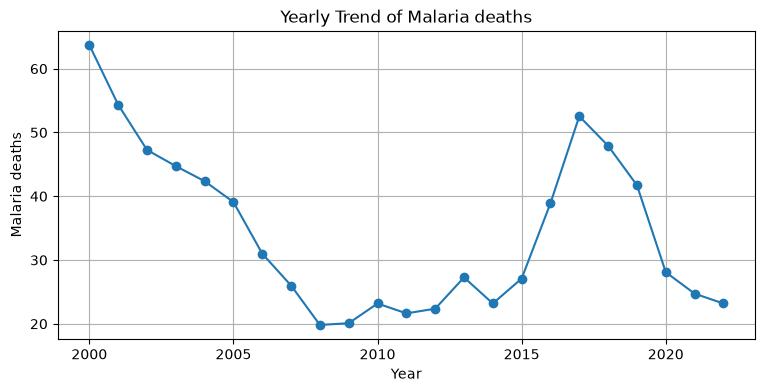

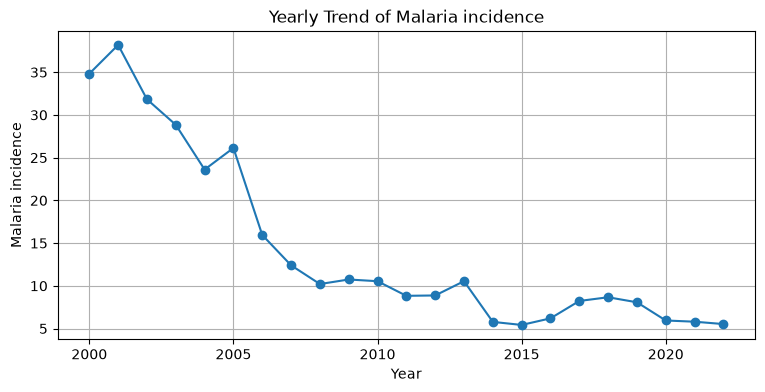

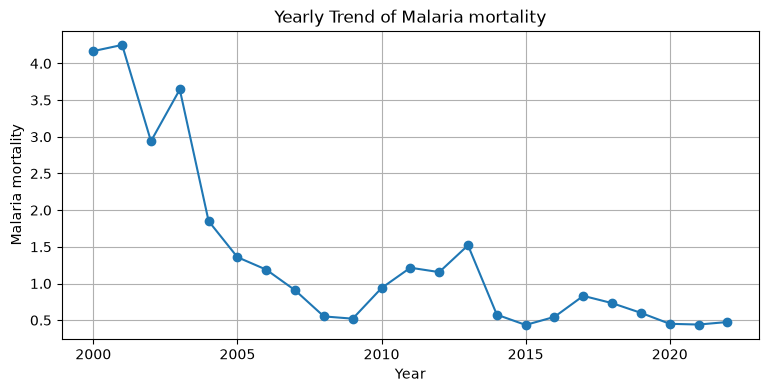

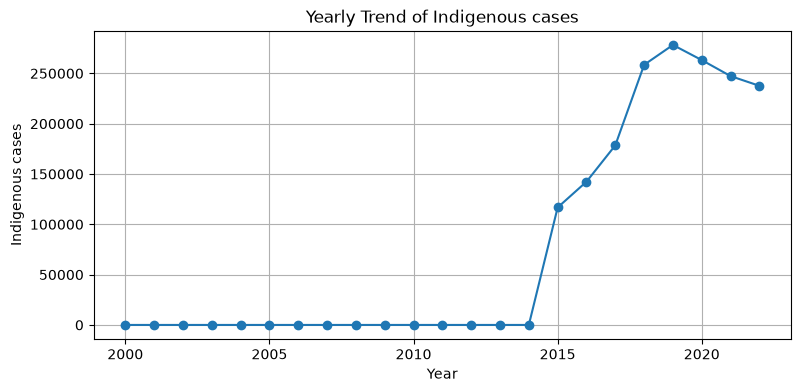

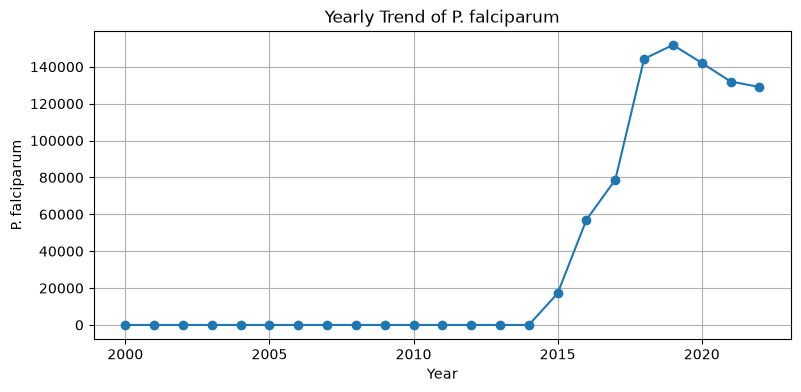

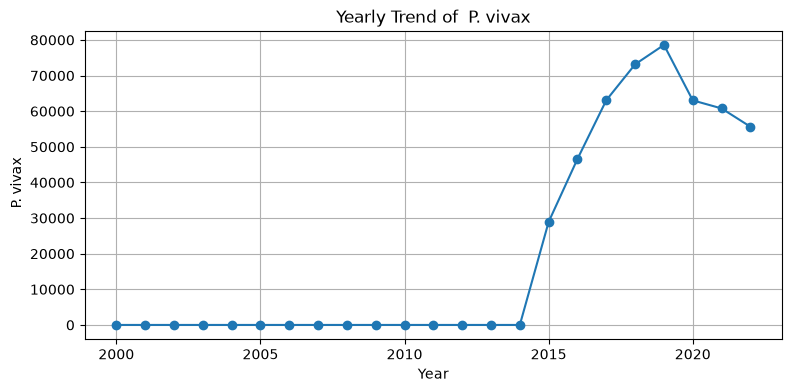

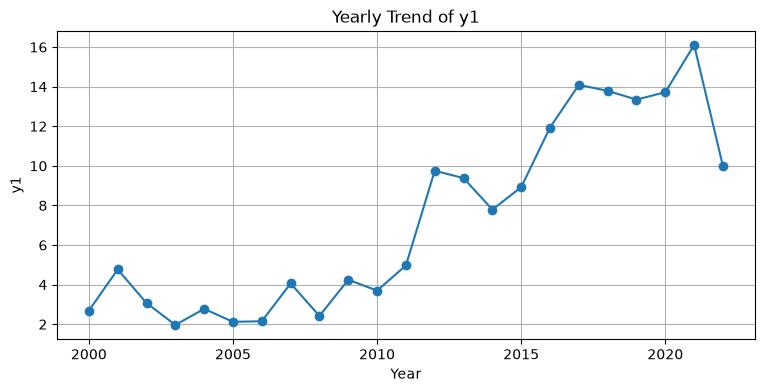

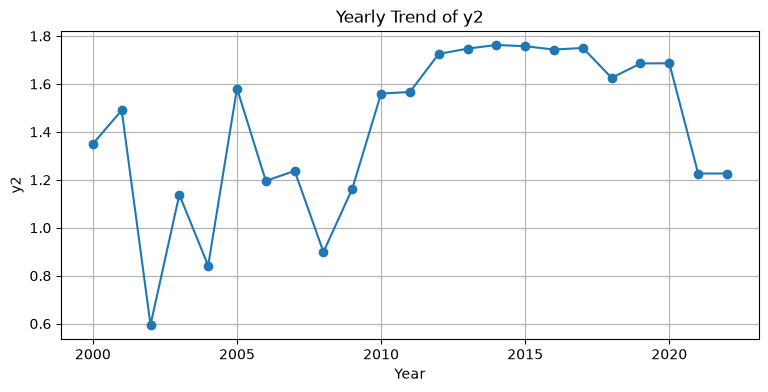

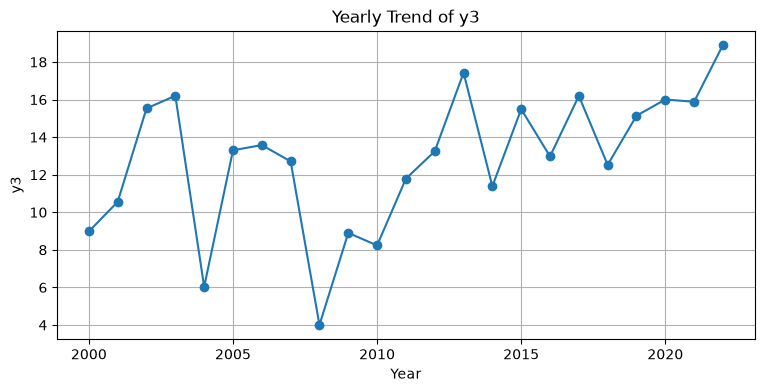

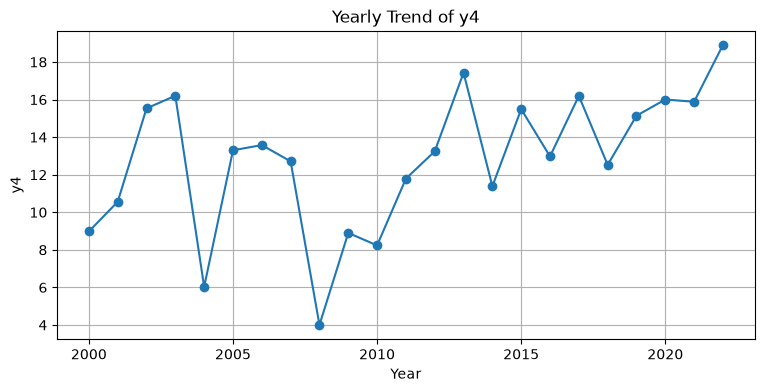

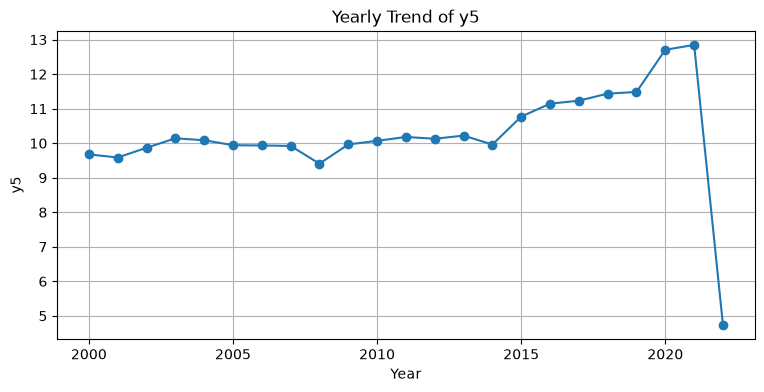

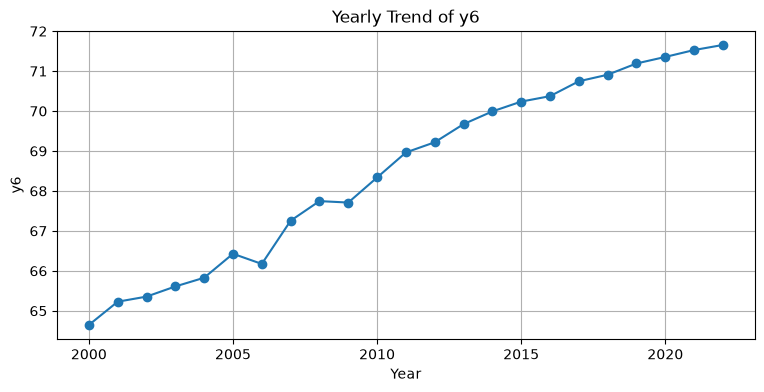

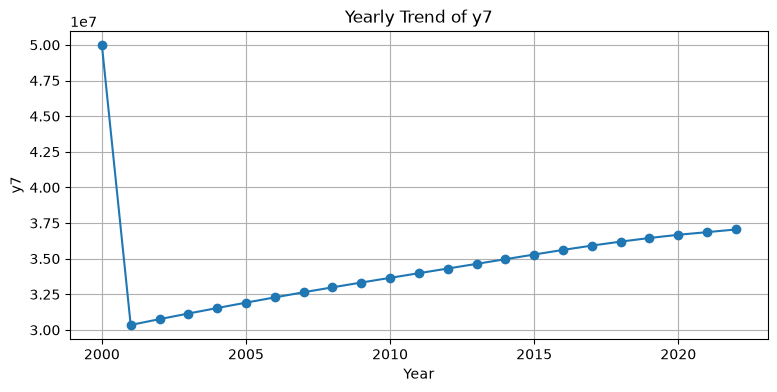

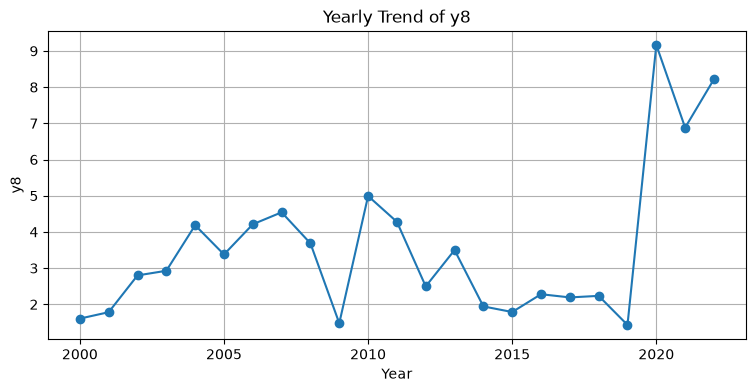

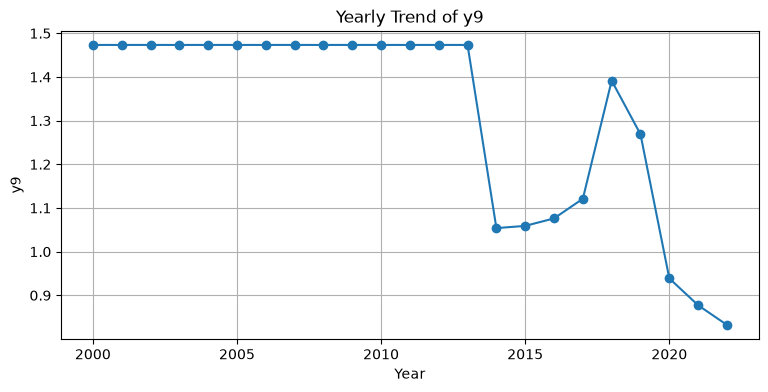

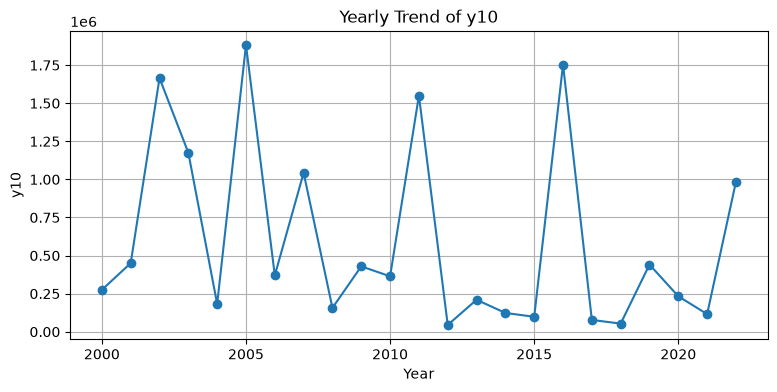

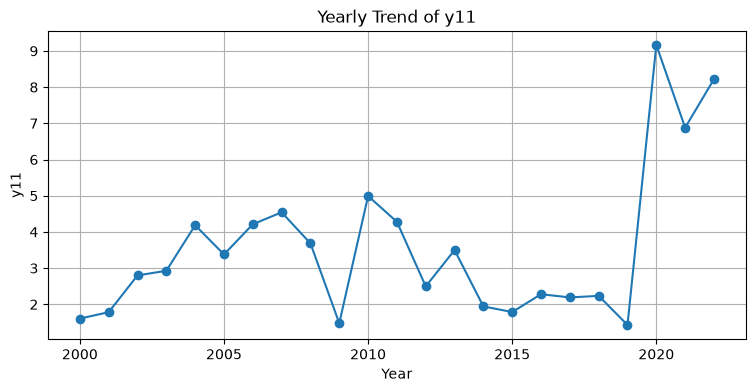

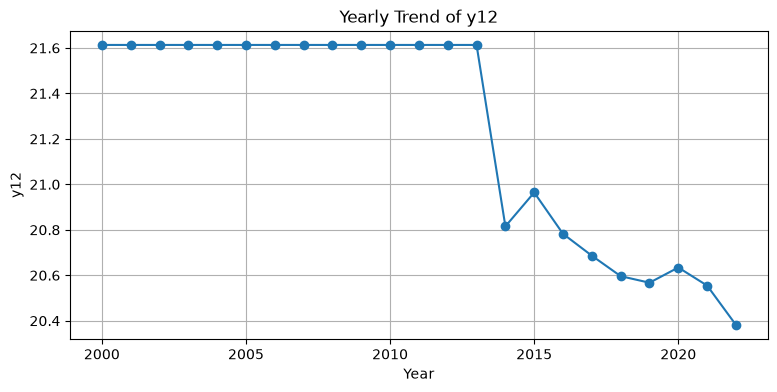

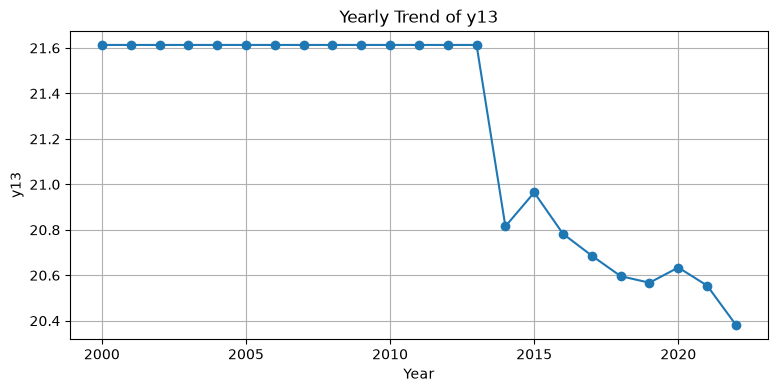

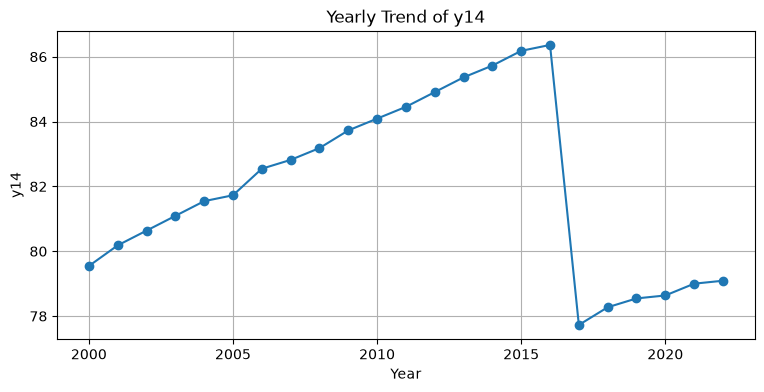

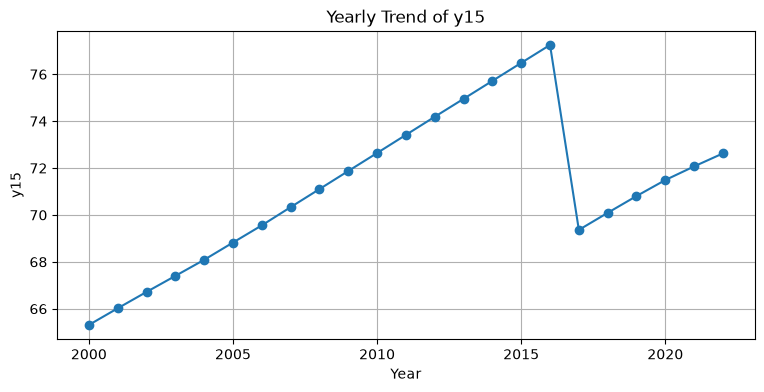

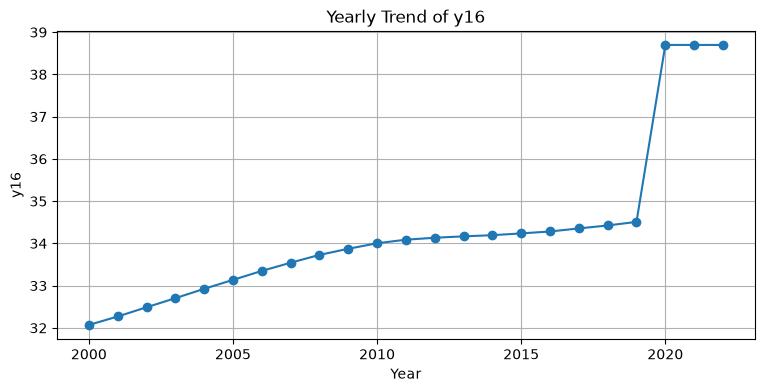

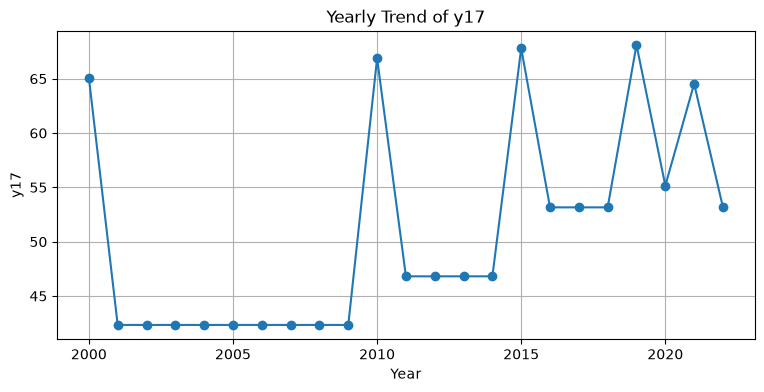

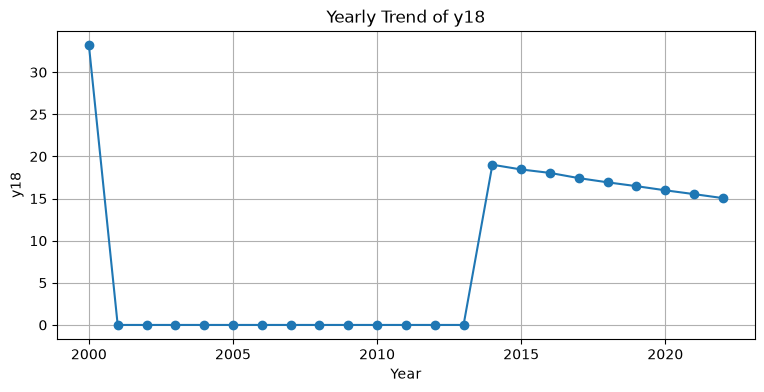

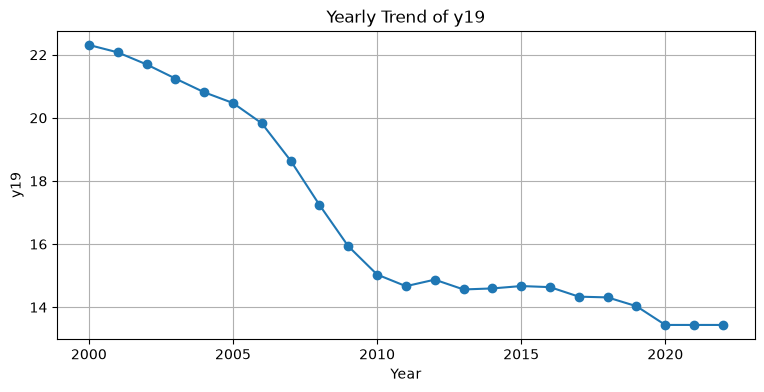

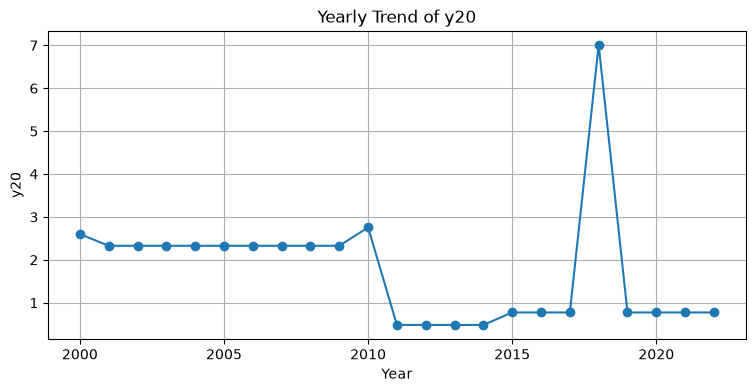

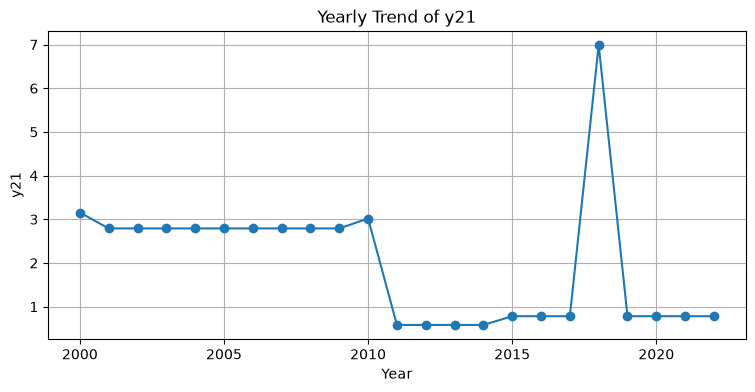

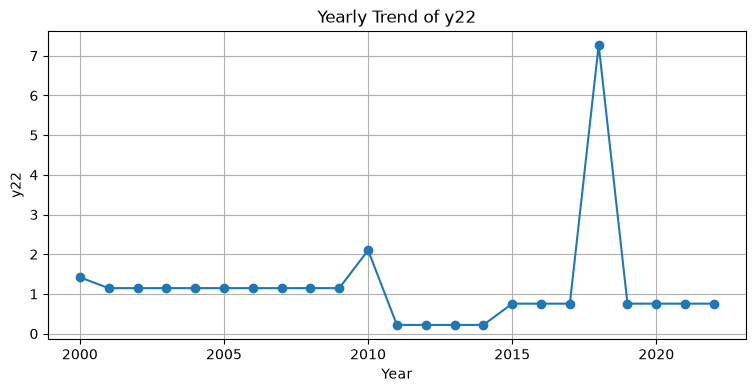

In [16]:
##year wise analysis###


# Find year column automatically
year_col = next(
    (c for c in data.columns if c.lower() == "year"),
    None
)

if year_col:
    yearly_mean = data.groupby(year_col)[num_vars].mean()

    print(yearly_mean.round(3))

    for col in num_vars:
        plt.figure(figsize=(9, 4))
        plt.plot(yearly_mean.index, yearly_mean[col],
                 marker="o")

        plt.title(f"Yearly Trend of {col}")
        plt.xlabel("Year")
        plt.ylabel(col)
        plt.grid(True)
        plt.show()
else:
    print("Year column not found. Check data.columns.")

In [17]:
#VIF and multicollinearity


import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1. Select independent variables
X_variables = [
    'y1','y2','y3','y4','y5','y6',
    'y8','y9','y10','y11','y12','y13',
    'y14','y15','y16','y17','y18','y19',
    'y20','y21','y22'
]

# 2. Convert into numeric
for col in X_variables:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# 3. Remove missing values
X = data[X_variables].dropna()

# 4. Remove constant variables
X = X.loc[:, X.nunique() > 1]

# 5. Calculate VIF
X_const = sm.add_constant(X)

vif = pd.DataFrame()
vif['Variable'] = X.columns
vif['VIF'] = [
    variance_inflation_factor(X_const.values, i+1)
    for i in range(len(X.columns))
]

# 6. Decision
vif['Decision'] = np.where(
    vif['VIF'] > 10,
    'High Multicollinearity',
    np.where(vif['VIF'] >= 5,
             'Moderate Multicollinearity',
             'Acceptable')
)

# 7. Display result
print(vif.round(3).to_string(index=False))

# 8. Save result
vif.to_excel('VIF_Results.xlsx', index=False)

C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


Variable       VIF                   Decision
      y1     2.248                 Acceptable
      y2     1.721                 Acceptable
      y3       inf     High Multicollinearity
      y4       inf     High Multicollinearity
      y5     2.882                 Acceptable
      y6     5.313 Moderate Multicollinearity
      y8       inf     High Multicollinearity
      y9     2.762                 Acceptable
     y10     1.063                 Acceptable
     y11       inf     High Multicollinearity
     y12       inf     High Multicollinearity
     y13       inf     High Multicollinearity
     y14    15.752     High Multicollinearity
     y15    13.501     High Multicollinearity
     y16     3.952                 Acceptable
     y17     4.768                 Acceptable
     y18     1.884                 Acceptable
     y19     3.171                 Acceptable
     y20 24466.273     High Multicollinearity
     y21 15815.618     High Multicollinearity
     y22  1107.940     High Multic

In [18]:
#Univariate poisson,adjusted poisson
import pandas as pd
import numpy as np
import statsmodels.api as sm
from scipy.stats import chi2

# 1. Define variables
Y = 'Malaria cases'

X_variables = [
    'y1','y2','y3','y4','y5','y6',
    'y8','y9','y10','y11','y12','y13',
    'y14','y15','y16','y17','y18','y19',
    'y20','y21','y22'
]

# 2. Convert into numeric
for col in [Y, 'y7'] + X_variables:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# 3. Select complete observations
d = data[[Y, 'y7'] + X_variables].dropna().copy()
d = d[d['y7'] > 0].copy()

print("Observations:", len(d))

# 4. Fit full multivariable model
full_model = sm.GLM(
    d[Y],
    sm.add_constant(d[X_variables]),
    family=sm.families.Poisson(),
    offset=np.log(d['y7'])
).fit()

# 5. Test each variable
results = []

for x in X_variables:

    # Univariate model
    uni_model = sm.GLM(
        d[Y],
        sm.add_constant(d[[x]]),
        family=sm.families.Poisson(),
        offset=np.log(d['y7'])
    ).fit()

    # Reduced model (without x)
    reduced_X = [v for v in X_variables if v != x]

    reduced_model = sm.GLM(
        d[Y],
        sm.add_constant(d[reduced_X]),
        family=sm.families.Poisson(),
        offset=np.log(d['y7'])
    ).fit()

    # Likelihood Ratio Test
    LR = reduced_model.deviance - full_model.deviance
    df_diff = full_model.df_model - reduced_model.df_model
    LRT_p = chi2.sf(max(LR, 0), df_diff)

    results.append({
        'Variable': x,
        'Univariate_P': uni_model.pvalues[x],
        'Adjusted_P': full_model.pvalues[x],
        'IRR': np.exp(full_model.params[x]),
        'LRT_P': LRT_p
    })

# 6. Display results
result = pd.DataFrame(results)

print("\nVariable Importance Results:")
print(result.round(4).to_string(index=False))

# 7. Save results
result.to_excel(
    'Variable_Importance_Results.xlsx',
    index=False
)

Observations: 253

Variable Importance Results:
Variable  Univariate_P  Adjusted_P    IRR  LRT_P
      y1           0.0         0.0 1.0063    0.0
      y2           0.0         0.0 0.8360    0.0
      y3           0.0         0.0 0.9895    NaN
      y4           0.0         0.0 0.9895    NaN
      y5           0.0         0.0 0.9191    0.0
      y6           0.0         0.0 1.0076    0.0
      y8           0.0         0.0 1.0125    NaN
      y9           0.0         0.0 2.7920    0.0
     y10           0.0         0.0 1.0000    0.0
     y11           0.0         0.0 1.0125    NaN
     y12           0.0         0.0 0.9961    NaN
     y13           0.0         0.0 0.9961    NaN
     y14           0.0         0.0 0.9980    0.0
     y15           0.0         0.0 1.0099    0.0
     y16           0.0         0.0 0.9923    0.0
     y17           0.0         0.0 0.9847    0.0
     y18           0.0         0.0 1.0204    0.0
     y19           0.0         0.0 1.0066    0.0
     y20           0.

In [19]:
# Check variation and correlation

X_variables = [
    'y1','y2','y3','y4','y5','y6',
    'y8','y9','y10','y11','y12','y13',
    'y14','y15','y16','y17','y18','y19',
    'y20','y21','y22'
]

# Check unique values
print("Unique values of each variable:")

for x in X_variables:
    print(x, data[x].nunique())

# Correlation matrix
corr = data[X_variables].corr()

print("\nCorrelation Matrix:")
print(corr.round(2))

# Save correlation matrix
corr.to_excel("Correlation_Matrix.xlsx")

Unique values of each variable:
y1 96
y2 106
y3 215
y4 215
y5 204
y6 97
y8 185
y9 101
y10 147
y11 185
y12 81
y13 81
y14 25
y15 218
y16 170
y17 56
y18 87
y19 169
y20 7
y21 7
y22 7

Correlation Matrix:
       y1    y2    y3    y4    y5    y6    y8    y9   y10   y11  ...   y13  \
y1   1.00  0.41  0.30  0.30  0.39  0.32  0.05 -0.07 -0.05  0.05  ...  0.45   
y2   0.41  1.00  0.10  0.10  0.33  0.34  0.16  0.04  0.12  0.16  ...  0.15   
y3   0.30  0.10  1.00  1.00  0.30  0.16  0.05  0.20  0.00  0.05  ...  0.28   
y4   0.30  0.10  1.00  1.00  0.30  0.16  0.05  0.20  0.00  0.05  ...  0.28   
y5   0.39  0.33  0.30  0.30  1.00  0.58  0.23  0.30  0.01  0.23  ...  0.63   
y6   0.32  0.34  0.16  0.16  0.58  1.00  0.39 -0.02  0.08  0.39  ...  0.51   
y8   0.05  0.16  0.05  0.05  0.23  0.39  1.00 -0.08  0.03  1.00  ...  0.10   
y9  -0.07  0.04  0.20  0.20  0.30 -0.02 -0.08  1.00  0.03 -0.08  ...  0.23   
y10 -0.05  0.12  0.00  0.00  0.01  0.08  0.03  0.03  1.00  0.03  ... -0.00   
y11  0.05  0.16  0.0